# Data Preprocessing: Integrated Practical Assessment
**Topic:** Missing Data, Imputation Methods, and KNN Imputer  
**Dataset:** `employee_preprocessing_assessment.csv`

**Approach:** inspect first, form hypotheses about *why* data is missing, then choose imputation methods with a justification. Every decision below is explained in a markdown cell.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

---
# Task 1: Data inspection and quality checks

In [2]:
# If running in Google Colab, upload the CSV first (files icon on the left) or use files.upload().
raw = pd.read_csv("employee_preprocessing_assessment.csv")
print("Shape (rows, columns):", raw.shape)
raw.head(10)

Shape (rows, columns): (152, 9)


,Employee_ID,Age,Experience_Years,Monthly_Salary,Projects_Completed,Satisfaction_Score,Department,Remote_Work,Performance_Rating
0,E001,24.0,0.0,42924.0,4.0,5.0,IT,Yes,Medium
1,E002,51.0,27.0,143599.0,4.0,4.0,Finance,No,High
2,E003,47.0,NaN,84579.0,2.0,5.0,IT,No,High
3,E004,38.0,13.0,68101.0,4.0,NaN,IT,No,Medium
4,E005,38.0,11.0,50754.0,5.0,5.0,Operations,No,Medium
5,E006,55.0,25.0,126192.0,2.0,4.0,Operations,Yes,Low
6,E007,NaN,2.0,35647.0,3.0,2.0,NaN,No,High
7,E008,48.0,20.0,136751.0,3.0,4.0,Operations,Yes,NaN
8,E009,29.0,1.0,34024.0,5.0,4.0,NaN,Yes,Medium
9,E010,24.0,0.0,41758.0,3.0,1.0,IT,No,Low


In [3]:
print("Data types:")
print(raw.dtypes)
print()
raw.info()

Data types:
Employee_ID               str
Age                   float64
Experience_Years      float64
Monthly_Salary        float64
Projects_Completed    float64
Satisfaction_Score    float64
Department                str
Remote_Work               str
Performance_Rating        str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         152 non-null    str    
 1   Age                 143 non-null    float64
 2   Experience_Years    144 non-null    float64
 3   Monthly_Salary      141 non-null    float64
 4   Projects_Completed  152 non-null    float64
 5   Satisfaction_Score  134 non-null    float64
 6   Department          145 non-null    str    
 7   Remote_Work         152 non-null    str    
 8   Performance_Rating  143 non-null    str    
dtypes: float64(5), str(4)
memory usage: 10.8 KB


In [4]:
# Descriptive statistics: numerical columns, then categorical columns
display(raw.describe().T.round(2))
display(raw.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
Age,143.0,41.15,10.82,21.0,32.0,42.0,51.0,60.0
Experience_Years,144.0,14.53,11.01,0.0,5.0,14.5,24.0,37.0
Monthly_Salary,141.0,83886.76,43389.67,22000.0,45498.0,80536.0,117402.0,180000.0
Projects_Completed,152.0,4.73,2.19,1.0,3.0,5.0,7.0,8.0
Satisfaction_Score,134.0,3.51,1.16,1.0,3.0,4.0,4.0,5.0


,count,unique,top,freq
Employee_ID,152,150,E008,2
Department,145,5,IT,48
Remote_Work,152,2,No,81
Performance_Rating,143,3,Medium,76


### Duplicate checks
Two kinds of duplicates exist: **fully identical rows**, and **repeated Employee_IDs** (an ID should be unique per person).

In [5]:
full_dups = raw.duplicated(keep=False)
print("Rows that are exact duplicates (incl. first copy):", full_dups.sum())
print("Duplicate rows that would be dropped:", raw.duplicated().sum())
print("Repeated Employee_IDs:", raw["Employee_ID"].duplicated().sum())
raw[full_dups].sort_values("Employee_ID")

Rows that are exact duplicates (incl. first copy): 4
Duplicate rows that would be dropped: 2
Repeated Employee_IDs: 2


,Employee_ID,Age,Experience_Years,Monthly_Salary,Projects_Completed,Satisfaction_Score,Department,Remote_Work,Performance_Rating
7,E008,48.0,20.0,136751.0,3.0,4.0,Operations,Yes,NaN
150,E008,48.0,20.0,136751.0,3.0,4.0,Operations,Yes,NaN
22,E023,28.0,0.0,22000.0,7.0,NaN,HR,No,High
151,E023,28.0,0.0,22000.0,7.0,NaN,HR,No,High


In [6]:
# Are the repeated IDs also fully identical rows? (if yes, it is safe to drop them)
dup_ids = raw.loc[raw["Employee_ID"].duplicated(keep=False), "Employee_ID"].unique()
print("Repeated IDs:", dup_ids)
print("Dropping exact duplicates also removes all repeated IDs:",
      raw.drop_duplicates()["Employee_ID"].is_unique)

Repeated IDs: <StringArray>
['E008', 'E023']
Length: 2, dtype: str
Dropping exact duplicates also removes all repeated IDs: True


**Decision:** both duplicated IDs (E008, E023) are *exact* copies of an earlier row, so these are accidental double entries. I drop them (152 → 150 rows). Duplicates matter for imputation because a repeated record gets double weight in means, medians and KNN neighbour searches.

In [7]:
# Remove duplicates; work on `df` from here on
df = raw.drop_duplicates().reset_index(drop=True)
print("Shape after de-duplication:", df.shape)

# Unique values in categorical columns (dropna=False so missing shows up as a category)
for col in ["Department", "Remote_Work", "Performance_Rating"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Shape after de-duplication: (150, 9)

Department:
Department
IT            48
Operations    28
HR            24
Finance       23
Marketing     20
NaN            7
Name: count, dtype: int64

Remote_Work:
Remote_Work
No     80
Yes    70
Name: count, dtype: int64

Performance_Rating:
Performance_Rating
Medium    76
High      39
Low       27
NaN        8
Name: count, dtype: int64


### Other data-quality checks
I check for impossible values (range checks), logical consistency (experience vs age), spelling/whitespace problems in categories, and suspicious repeated values (floors/caps).

In [8]:
num_cols = ["Age", "Experience_Years", "Monthly_Salary", "Projects_Completed", "Satisfaction_Score"]

# 1) Range / plausibility checks
print("Age range:", df["Age"].min(), "-", df["Age"].max())
print("Satisfaction_Score values:", sorted(df["Satisfaction_Score"].dropna().unique()))
print("Projects_Completed values:", sorted(df["Projects_Completed"].dropna().unique()))
print("Negative values anywhere?", (df[num_cols] < 0).any().any())

# 2) Logical consistency: someone cannot have started working before ~age 15
both = df.dropna(subset=["Age", "Experience_Years"])
bad = both[both["Experience_Years"] > both["Age"] - 15]
print("\nRows where Experience_Years > Age - 15 (impossible):", len(bad))

# 3) Hidden whitespace / case problems in categorical text
for col in ["Department", "Remote_Work", "Performance_Rating"]:
    s = df[col].dropna()
    print(col, "-> values with stray whitespace:", (s != s.str.strip()).sum())

# 4) Suspicious repeated values: floor/cap in salary
print("\nMost frequent salary values:")
print(df["Monthly_Salary"].value_counts().head(3))
print("Min salary:", df["Monthly_Salary"].min(), "| Max salary:", df["Monthly_Salary"].max())

# 5) Skewness (guides mean vs median later)
print("\nSkewness:")
print(df[num_cols].skew().round(2))

Age range: 21.0 - 60.0
Satisfaction_Score values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Projects_Completed values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0)]
Negative values anywhere? False

Rows where Experience_Years > Age - 15 (impossible): 0
Department -> values with stray whitespace: 0
Remote_Work -> values with stray whitespace: 0
Performance_Rating -> values with stray whitespace: 0

Most frequent salary values:
Monthly_Salary
22000.0     5
180000.0    2
42924.0     1
Name: count, dtype: int64
Min salary: 22000.0 | Max salary: 180000.0

Skewness:
Age                  -0.20
Experience_Years      0.11
Monthly_Salary        0.28
Projects_Completed   -0.12
Satisfaction_Score   -0.56
dtype: float64


**Data-quality findings**
- **No impossible values:** ages 21-60, satisfaction 1-5, projects 1-8, no negatives, and experience is always consistent with age.
- **Salary floor and cap:** `Monthly_Salary = 22000` appears 5 times (after de-duplication) and `180000` appears twice. Real salaries are rarely exactly the same, so these look like a **minimum wage floor / reporting cap** (censoring). This matters for imputation: the real values below/above these limits are unknown.
- **Many `Experience_Years = 0`:** fresh joiners; this is valid, but it makes the column spiky (not a smooth distribution).
- **Category labels are clean** (no spelling variants). Missing values are plain `NaN`.
- **Age and Experience_Years are almost perfectly correlated** (about 0.95) and both correlate with salary (about 0.9). This is the key structure that KNN imputation can exploit later.

### Column roles
| Column | Role | Reason |
|---|---|---|
| `Employee_ID` | **Identifier** | Unique label per person, carries no predictive meaning. It is excluded from imputation and modelling. |
| `Age`, `Experience_Years`, `Monthly_Salary`, `Projects_Completed` | **Numerical** (continuous or count) | Measured quantities where distances and averages make sense. |
| `Satisfaction_Score` | **Numerical, but ordinal** (1-5 scale) | Numeric codes, but the gaps between levels are subjective; treated as numeric for KNN, with the limitation noted. |
| `Department`, `Remote_Work` | **Categorical (nominal)** | Labels with no order. |
| `Performance_Rating` | **Categorical (ordinal)** | Low < Medium < High has an order, but it is stored as text. |

---
# Task 2: Missingness analysis and visualization

In [9]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "observed_count": df.notna().sum()
}).sort_values("missing_percent", ascending=False)
display(missing_summary)
print("Rows with at least one missing value:", df.isna().any(axis=1).sum(), "of", len(df))
print("Total missing cells:", df.isna().sum().sum())

,missing_count,missing_percent,observed_count
Satisfaction_Score,17,11.33,133
Monthly_Salary,11,7.33,139
Age,9,6.00,141
Performance_Rating,8,5.33,142
Experience_Years,8,5.33,142
Department,7,4.67,143
Employee_ID,0,0.00,150
Projects_Completed,0,0.00,150
Remote_Work,0,0.00,150


Rows with at least one missing value: 52 of 150
Total missing cells: 60


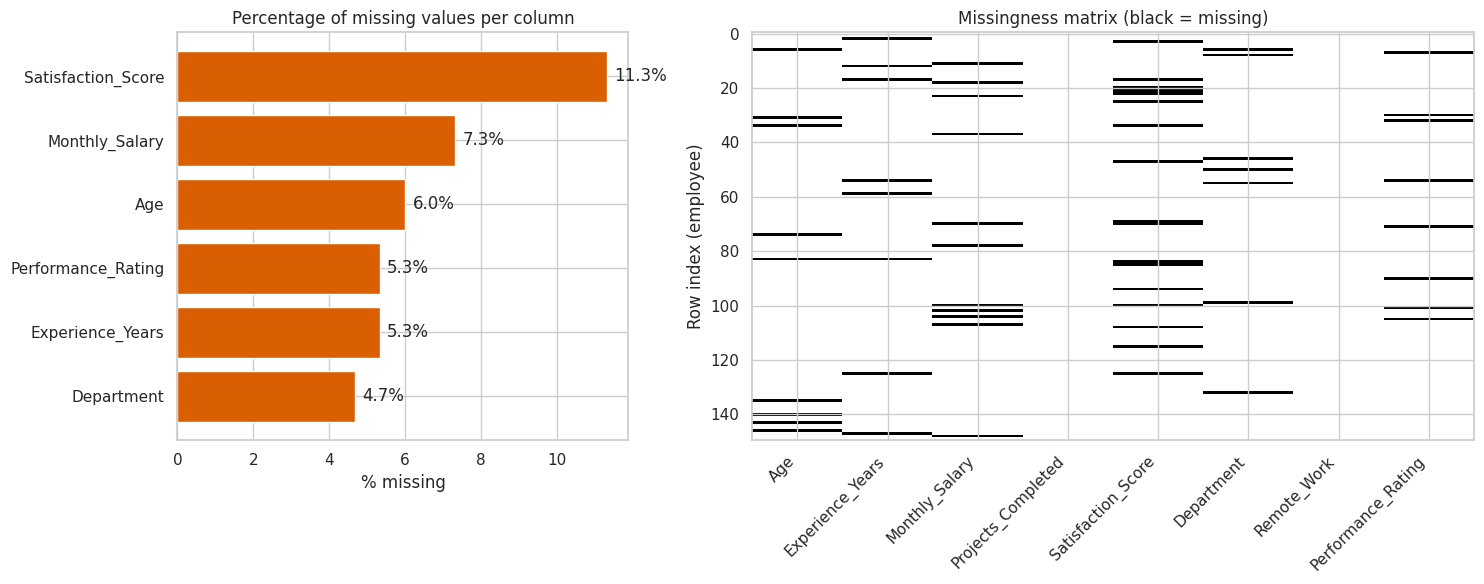

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: % missing per column
ms = missing_summary[missing_summary["missing_count"] > 0]
axes[0].barh(ms.index, ms["missing_percent"], color="#d95f02")
axes[0].invert_yaxis()
axes[0].set_xlabel("% missing")
axes[0].set_title("Percentage of missing values per column")
for i, v in enumerate(ms["missing_percent"]):
    axes[0].text(v + 0.2, i, f"{v:.1f}%", va="center")

# Right: missingness matrix (each row = employee, dark cell = missing)
cols = [c for c in df.columns if c != "Employee_ID"]
axes[1].imshow(df[cols].isna().values, aspect="auto", cmap="Greys", interpolation="nearest")
axes[1].set_xticks(range(len(cols)))
axes[1].set_xticklabels(cols, rotation=45, ha="right")
axes[1].set_ylabel("Row index (employee)")
axes[1].set_title("Missingness matrix (black = missing)")
plt.tight_layout()
plt.show()

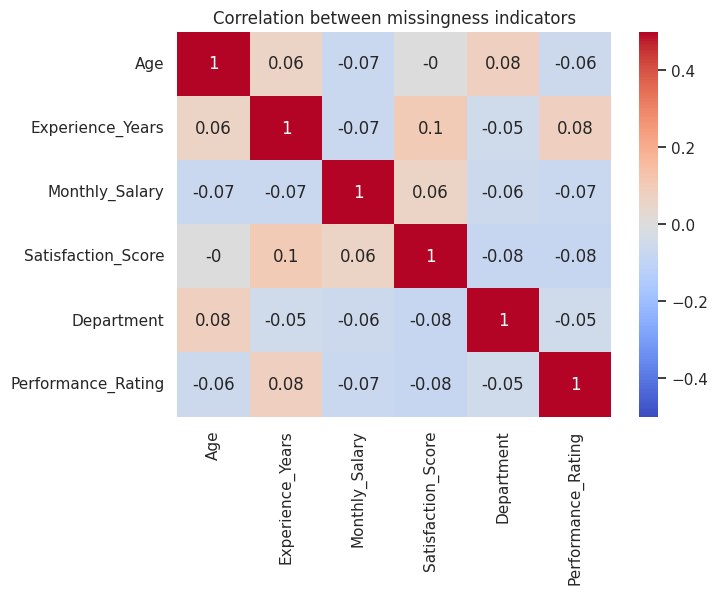

Number of missing values per row:
0    98
1    44
2     8
Name: count, dtype: int64


In [11]:
# Heatmap of the *correlation between missingness indicators*:
# do values tend to go missing together?
miss_ind = df[cols].isna().astype(int)
miss_ind = miss_ind.loc[:, miss_ind.sum() > 0]
plt.figure(figsize=(7, 5))
sns.heatmap(miss_ind.corr().round(2), annot=True, cmap="coolwarm", center=0, vmin=-0.5, vmax=0.5)
plt.title("Correlation between missingness indicators")
plt.show()

print("Number of missing values per row:")
print(df.isna().sum(axis=1).value_counts().sort_index())

### Is the missingness clustered, or related to observed features?
**Not clustered across columns:** the indicator correlations are close to zero, 98 of 150 rows are fully complete, 44 rows miss one value and only 8 rows miss two. Values are not going missing together in blocks, and the matrix looks scattered rather than banded.

Next I check whether missingness is **associated with the observed values** of other columns. For each column with missing data I compare the mean of the other numeric features between rows where it is missing vs. observed, plus a Mann-Whitney U test (a non-parametric test, suitable for skewed or small samples).

In [12]:
rows = []
for target in ["Age", "Experience_Years", "Monthly_Salary", "Satisfaction_Score"]:
    is_miss = df[target].isna()
    for other in num_cols:
        if other == target:
            continue
        a, b = df.loc[is_miss, other].dropna(), df.loc[~is_miss, other].dropna()
        p = stats.mannwhitneyu(a, b).pvalue
        rows.append({"column_with_NaN": target, "compared_feature": other,
                     "mean_when_missing": round(a.mean(), 1), "mean_when_observed": round(b.mean(), 1),
                     "p_value": round(p, 3)})
assoc = pd.DataFrame(rows)
display(assoc)

,column_with_NaN,compared_feature,mean_when_missing,mean_when_observed,p_value
0,Age,Experience_Years,11.9,14.8,0.483
1,Age,Monthly_Salary,82265.6,84068.4,0.894
2,Age,Projects_Completed,4.0,4.8,0.301
3,Age,Satisfaction_Score,3.2,3.5,0.470
4,Experience_Years,Age,40.6,41.2,0.853
5,Experience_Years,Monthly_Salary,84742.0,83903.4,0.867
6,Experience_Years,Projects_Completed,3.9,4.8,0.228
7,Experience_Years,Satisfaction_Score,3.3,3.5,0.532
8,Monthly_Salary,Age,52.7,40.2,0.000
9,Monthly_Salary,Experience_Years,26.9,13.6,0.000


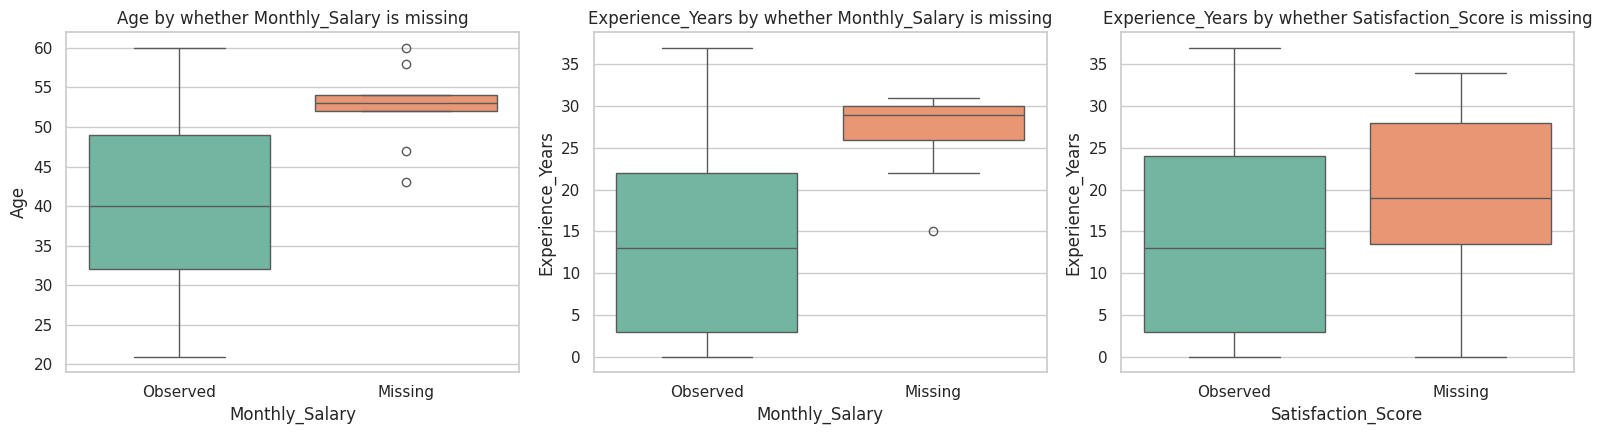

Department missing: mean Age = 31.7 vs observed 41.6


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (target, feat) in zip(axes, [("Monthly_Salary", "Age"), ("Monthly_Salary", "Experience_Years"), ("Satisfaction_Score", "Experience_Years")]):
    sns.boxplot(x=df[target].isna().map({True: "Missing", False: "Observed"}), y=df[feat], ax=ax, palette="Set2")
    ax.set_title(f"{feat} by whether {target} is missing")
    ax.set_xlabel(target)
plt.tight_layout()
plt.show()

# Is the missingness of Department related to other features (e.g., younger staff)?
d = df["Department"].isna()
print("Department missing: mean Age =", round(df.loc[d, "Age"].mean(), 1), "vs observed", round(df.loc[~d, "Age"].mean(), 1))

### Interpretation
- **`Monthly_Salary`: strongly associated with observed features.** Rows with a missing salary are much older (mean age about 53 vs 40) and more experienced (about 27 vs 14 years), with p-values near 0. Missingness depends on **observed** variables, which is the signature of **MAR** (or at least not MCAR).
- **`Satisfaction_Score`:** missing rows have somewhat higher experience and salary, but the differences are **not significant** (p about 0.10 and 0.26). There is only weak evidence of a pattern.
- **`Experience_Years` and `Age`:** no significant association with the other columns (p > 0.2), consistent with **MCAR**, but this is not proof.
- **`Department`:** missing rows tend to be younger (mean age about 32 vs 42, p about 0.03), a mild association. With only 7 missing values this test has little power.

### Why percentages or a heatmap alone cannot prove MCAR, MAR or MNAR
1. **Missing percentages** only say *how much* is missing, never *why*. The same 7% could come from random loss (MCAR) or from high earners hiding their salary (MNAR).
2. **A heatmap or missingness matrix** shows *where* values are missing. It can show clustering, but absence of a visible pattern does not prove randomness, and a pattern does not tell you the cause.
3. **MNAR depends on the unobserved values themselves.** If salary is missing *because* it is high, the data needed to test that is exactly what is missing. No test on the observed data can prove it.
4. **Tests on observed variables can only support MAR over MCAR**, and only for the variables I happened to compare. A non-significant test with n = 8 or 18 missing values may simply lack power.
5. Establishing the mechanism needs **domain knowledge or extra information** (how the data was collected, a follow-up survey of non-responders).

---
# Task 3: MCAR, MAR and MNAR

### Definitions (own words)
- **MCAR (Missing Completely At Random):** whether a value is missing has nothing to do with any variable, observed or not. It is like a coin flip. Complete rows are an unbiased sample of all rows.
- **MAR (Missing At Random):** missingness depends on **other observed variables**, but not on the missing value itself once those are accounted for. The pattern can be explained using the data we have.
- **MNAR (Missing Not At Random):** missingness depends on the **missing value itself** (or on something unobserved related to it). The reason for being missing is hidden in the data we cannot see.

### One realistic example of each (employee data)
| Mechanism | Example |
|---|---|
| **MCAR** | A database migration glitch randomly drops some `Age` entries. Which employees are affected is unrelated to age, salary or anything else. |
| **MAR** | Senior employees (long experience) are more likely to skip the satisfaction survey because they are busier. Missingness depends on the *observed* `Experience_Years`. |
| **MNAR** | Employees who are very **unhappy** choose not to fill in `Satisfaction_Score`, or very **high earners** refuse to disclose `Monthly_Salary`. Missingness depends on the unobserved value. |

### The three columns in this dataset
| Column | Missing | Plausible mechanism (hypothesis) | Evidence in the observed data | What extra context/tests would be needed |
|---|---|---|---|---|
| `Experience_Years` | 8 (5.3%) | **MCAR** (data-entry or HR-system error) | No significant link to other features | Ask HR how this field is collected and whether blanks cluster by date or data-entry operator; compare with joining dates in payroll records. |
| `Satisfaction_Score` | 17 (11.3%) | **MAR** (seniority) or **MNAR** (unhappy employees skip the survey) | Slightly higher experience and salary when missing, but not significant | Survey response logs, follow-up survey of non-respondents, compare with exit-interview or attrition data. |
| `Monthly_Salary` | 11 (7.3%) | **MAR** on Age/Experience (senior staff records stored elsewhere or confidential), possibly **MNAR** (high earners withheld) | Strongly older and more experienced when missing (p near 0) | Confirm from HR whether executive or senior pay is kept in a separate confidential system (that would explain it as MAR). Compare with payroll totals or salary bands. |

### Hypothesis vs. what can be proven
- **What the data can show:** the *observed* data shows that salary missingness is associated with age and experience. That **rules out MCAR for salary** (a statistical conclusion about observed variables).
- **What it cannot show:** whether the mechanism is **MAR or MNAR**. Both produce the same observed pattern. If senior people are missing because of their age, that is MAR. If they are missing because their salaries are high, that is MNAR. The values needed to distinguish them are the missing ones.
- **For `Experience_Years` and `Satisfaction_Score`,** "looks MCAR" is only a hypothesis: absence of a detectable pattern is not proof of randomness.
- **Conclusion:** the mechanism can only be *hypothesised* with domain knowledge. I treat salary as **MAR-like** for imputation (using age and experience as predictors) and state clearly that MNAR cannot be excluded.

---
# Task 4: Imputation strategy (simple methods)

### Plan per column
| Column | Method | Reason |
|---|---|---|
| `Age` | **Mean** | Almost symmetric (skew about -0.2), so mean and median are nearly identical. |
| `Experience_Years` | **Median** | Discrete counts with a spike at 0 (many fresh joiners). The median is robust to that spike and is always a realistic value. Skew is small (0.11), so the mean would be similar. |
| `Monthly_Salary` | **Median** | Mildly right-skewed (skew 0.28) with floor/cap values piled at the extremes. The median is robust to those; mean and median are close here, so this is a safe-choice rather than a big-difference decision. |
| `Satisfaction_Score` | **Mode** | Ordinal 1-5 scale: the mean would produce non-existent values such as 3.51. The mode (most common rating) is a valid score. |
| `Performance_Rating` | **Mode** | Categorical: mean and median are undefined for text labels. |
| `Department` | **"Unknown" category** (mode shown for comparison) | Missing rows are mostly younger staff, and filling with the mode (IT) would invent a department for them. A separate category keeps the information that it is missing. |

Missing percentages are all below 12%, so **no column needs to be dropped**. As a rule of thumb, a feature is considered for removal when it is missing more than about 40-50% *and* has little predictive value. For the two columns with the highest missingness (`Satisfaction_Score`, `Monthly_Salary`), I will add **missingness indicator** columns, because being missing may itself carry information (e.g., seniority or non-response).

In [14]:
df_simple = df.copy()

# 1) Missingness indicators BEFORE imputing (otherwise the information is lost)
for c in ["Monthly_Salary", "Satisfaction_Score"]:
    df_simple[f"{c}_was_missing"] = df_simple[c].isna().astype(int)

# 2) Numerical columns
df_simple["Age"] = df_simple["Age"].fillna(df["Age"].mean())
df_simple["Experience_Years"] = df_simple["Experience_Years"].fillna(df["Experience_Years"].median())
df_simple["Monthly_Salary"] = df_simple["Monthly_Salary"].fillna(df["Monthly_Salary"].median())
df_simple["Satisfaction_Score"] = df_simple["Satisfaction_Score"].fillna(df["Satisfaction_Score"].mode()[0])

# 3) Categorical columns
df_simple["Performance_Rating"] = df_simple["Performance_Rating"].fillna(df["Performance_Rating"].mode()[0])
df_simple["Department"] = df_simple["Department"].fillna("Unknown")

print("Values used:")
print("  Age mean            :", round(df["Age"].mean(), 2))
print("  Experience median   :", df["Experience_Years"].median())
print("  Salary median       :", df["Monthly_Salary"].median())
print("  Satisfaction mode   :", df["Satisfaction_Score"].mode()[0])
print("  Performance mode    :", df["Performance_Rating"].mode()[0])
print("\nRemaining missing values:", df_simple.isna().sum().sum())

Values used:
  Age mean            : 41.19
  Experience median   : 14.5
  Salary median       : 80536.0
  Satisfaction mode   : 4.0
  Performance mode    : Medium

Remaining missing values: 0


In [15]:
# Comparison: mean vs median vs mode on Salary, to justify the choice
comp = pd.DataFrame({
    "original (observed only)": df["Monthly_Salary"].describe(),
    "mean-imputed": df["Monthly_Salary"].fillna(df["Monthly_Salary"].mean()).describe(),
    "median-imputed": df["Monthly_Salary"].fillna(df["Monthly_Salary"].median()).describe(),
}).round(1)
display(comp)
print("Skewness of Salary:", round(df["Monthly_Salary"].skew(), 2))
print("Note: mean (", round(df["Monthly_Salary"].mean()), ") vs median (", df["Monthly_Salary"].median(), ")")

,original (observed only),mean-imputed,median-imputed
count,139.0,150.0,150.0
mean,83951.7,83951.7,83701.2
std,43150.2,41526.9,41536.5
min,22000.0,22000.0,22000.0
25%,45891.0,47392.0,47392.0
50%,80536.0,83951.7,80536.0
75%,117184.0,116069.5,116069.5
max,180000.0,180000.0,180000.0


Skewness of Salary: 0.28
Note: mean ( 83952 ) vs median ( 80536.0 )


In [16]:
# Before vs after: summary statistics (numerical columns)
rows = []
for c in ["Age", "Experience_Years", "Monthly_Salary", "Satisfaction_Score"]:
    rows.append({"column": c,
                 "mean_before": df[c].mean(), "mean_after": df_simple[c].mean(),
                 "std_before": df[c].std(), "std_after": df_simple[c].std(),
                 "median_before": df[c].median(), "median_after": df_simple[c].median()})
before_after = pd.DataFrame(rows).set_index("column").round(2)
display(before_after)

,mean_before,mean_after,std_before,std_after,median_before,median_after
column,,,,,,
Age,41.19,41.19,10.82,10.49,42.0,41.19
Experience_Years,14.60,14.59,11.01,10.71,14.5,14.50
Monthly_Salary,83951.67,83701.19,43150.20,41536.48,80536.0,80536.00
Satisfaction_Score,3.51,3.57,1.16,1.10,4.0,4.00


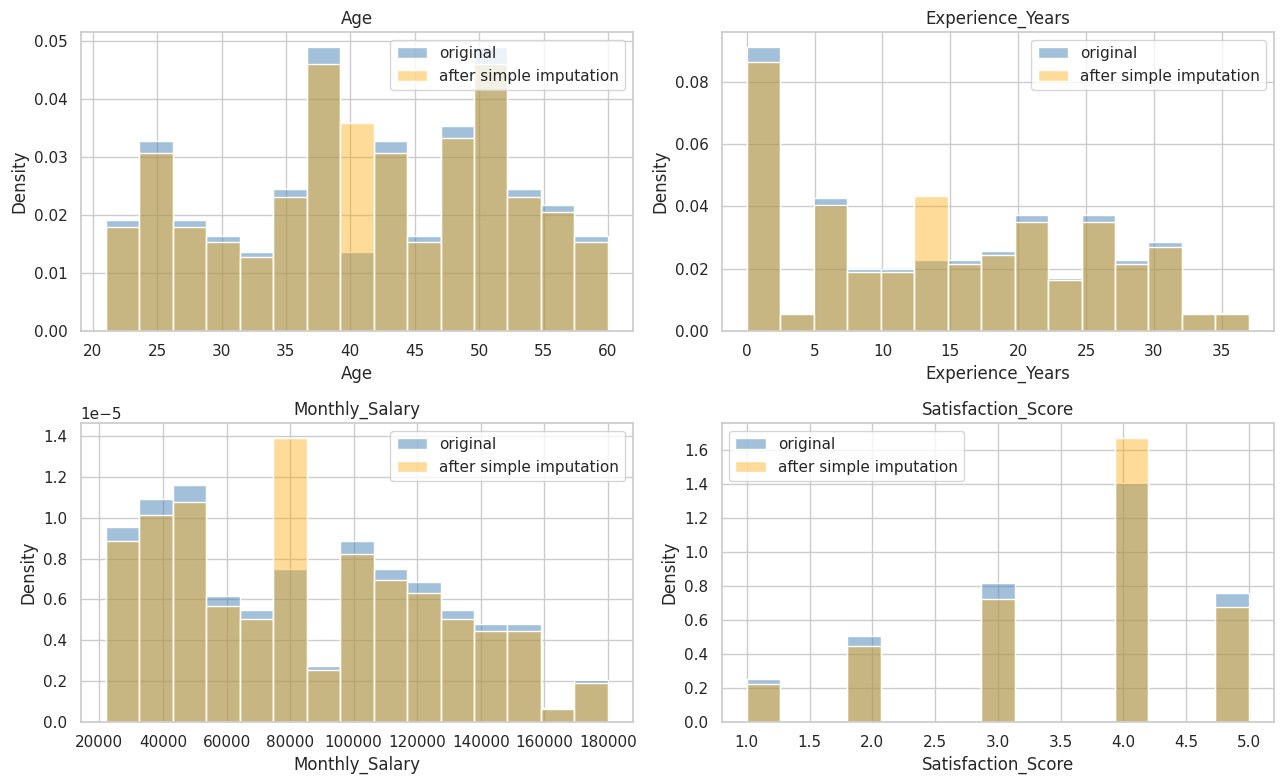

Corr(Age, Experience) before: 0.945
Corr(Age, Experience) after : 0.901
Corr(Experience, Salary) before: 0.959
Corr(Experience, Salary) after : 0.878

Department counts after (Unknown kept as own category):
Department
IT            48
Operations    28
HR            24
Finance       23
Marketing     20
Unknown        7
Name: count, dtype: int64


In [17]:
# Before vs after: distributions
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), ["Age", "Experience_Years", "Monthly_Salary", "Satisfaction_Score"]):
    sns.histplot(df[c].dropna(), color="steelblue", label="original", stat="density", alpha=0.5, ax=ax, bins=15)
    sns.histplot(df_simple[c], color="orange", label="after simple imputation", stat="density", alpha=0.4, ax=ax, bins=15)
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

# Effect on relationships: correlation between Age and Experience
print("Corr(Age, Experience) before:", round(df["Age"].corr(df["Experience_Years"]), 3))
print("Corr(Age, Experience) after :", round(df_simple["Age"].corr(df_simple["Experience_Years"]), 3))
print("Corr(Experience, Salary) before:", round(df["Experience_Years"].corr(df["Monthly_Salary"]), 3))
print("Corr(Experience, Salary) after :", round(df_simple["Experience_Years"].corr(df_simple["Monthly_Salary"]), 3))
print("\nDepartment counts after (Unknown kept as own category):")
print(df_simple["Department"].value_counts())

### Interpretation
- **Mean/median/mode imputation keeps the center but shrinks the spread.** Every imputed row gets the same value, which creates a spike at that value in the histogram and reduces the standard deviation. The effect is largest for `Satisfaction_Score` (17 values replaced by one number).
- **It also weakens relationships.** The Age-Experience and Experience-Salary correlations drop after imputation, because the imputed rows ignore each person's other attributes. A senior employee with missing salary gets the *overall median* salary, which is far too low. This is a real distortion, since the salary missingness is concentrated among older staff.
- **Mean vs. median for salary:** the skew here is mild (0.28), so the two values are close (about 83,952 vs 80,536). The median is still the safer default, because it is not pulled by extreme values; with a strongly skewed column (e.g. skew above 1) the gap would be much larger and the median clearly better. For a near-symmetric column like `Age` the two give nearly the same answer.
- **Mode for `Performance_Rating`** assigns "Medium" to all missing rows, which inflates the majority class. That is acceptable for a small fraction (6%), but it is another reason to be careful.
- **Conclusion:** simple imputation is a fine baseline for low-correlation columns, but for Salary, Experience and Age, where columns are strongly related, a method that **uses other columns (KNN)** should do better. This leads to Task 5.

---
# Task 5: KNN Imputer

### How KNNImputer works
For each row with a missing value, the algorithm:
1. Computes a **distance** to every other row that has a value in that column, using only the features that **both rows have observed** (an "nan-Euclidean" distance, rescaled for the number of coordinates used).
2. Picks the **k nearest** rows (the neighbours).
3. Fills the gap with the **average** of the neighbours' values for that column (with `weights="uniform"`; `weights="distance"` would give closer neighbours more influence).

So an older employee with a missing salary gets the average salary of the most *similar* employees (similar age, experience, projects, satisfaction), not the average of everyone.

### Why scale first?
The distance is computed on raw numbers. `Monthly_Salary` ranges over about 22,000-180,000 while `Satisfaction_Score` ranges 1-5, so salary differences would completely dominate the distance and the other features would be effectively ignored. **StandardScaler** (mean 0, std 1) puts all features on the same footing. `StandardScaler` ignores `NaN` when fitting, so it can be applied before imputing. After imputing I inverse-transform back to the original units.

In [18]:
knn_cols = ["Age", "Experience_Years", "Monthly_Salary", "Projects_Completed", "Satisfaction_Score"]
X = df[knn_cols].copy()
print("Missing before:\n", X.isna().sum())

def knn_impute(X, k, scale=True, weights="uniform"):
    """Scale (optional) -> KNN impute -> inverse scale. Returns a DataFrame in original units."""
    imputer = KNNImputer(n_neighbors=k, weights=weights)
    if scale:
        scaler = StandardScaler()
        Z = scaler.fit_transform(X)                    # NaNs are ignored when computing mean/std
        out = scaler.inverse_transform(imputer.fit_transform(Z))
    else:
        out = imputer.fit_transform(X)
    return pd.DataFrame(out, columns=X.columns, index=X.index)

X_knn3 = knn_impute(X, k=3)
X_knn5 = knn_impute(X, k=5)
X_knn3_unscaled = knn_impute(X, k=3, scale=False)

print("\nRemaining NaN after KNN (k=3):", X_knn3.isna().sum().sum())
print("Remaining NaN after KNN (k=5):", X_knn5.isna().sum().sum())

Missing before:
 Age                    9
Experience_Years       8
Monthly_Salary        11
Projects_Completed     0
Satisfaction_Score    17
dtype: int64

Remaining NaN after KNN (k=3): 0
Remaining NaN after KNN (k=5): 0


In [19]:
# Verify no missing values remain in the selected numerical columns
assert X_knn3.isna().sum().sum() == 0 and X_knn5.isna().sum().sum() == 0
print("Verified: no missing values remain in", knn_cols)
print(X_knn5.isna().sum())

Verified: no missing values remain in ['Age', 'Experience_Years', 'Monthly_Salary', 'Projects_Completed', 'Satisfaction_Score']
Age                   0
Experience_Years      0
Monthly_Salary        0
Projects_Completed    0
Satisfaction_Score    0
dtype: int64


### Comparing n_neighbors = 3 vs 5
Compare the actual imputed values for the same cells, and the summary statistics.

In [20]:
# Imputed salary cells: k=3 vs k=5 vs median
sal_idx = X.index[X["Monthly_Salary"].isna()]
cmp_sal = pd.DataFrame({
    "Employee_ID": df.loc[sal_idx, "Employee_ID"],
    "Age": df.loc[sal_idx, "Age"],
    "Experience_Years": df.loc[sal_idx, "Experience_Years"],
    "Salary_median": df["Monthly_Salary"].median(),
    "Salary_KNN3": X_knn3.loc[sal_idx, "Monthly_Salary"].round(0),
    "Salary_KNN5": X_knn5.loc[sal_idx, "Monthly_Salary"].round(0),
})
cmp_sal["abs_diff_3_vs_5"] = (cmp_sal["Salary_KNN3"] - cmp_sal["Salary_KNN5"]).abs()
display(cmp_sal)
print("Mean absolute difference between k=3 and k=5 on imputed salaries:", round(cmp_sal["abs_diff_3_vs_5"].mean()))

,Employee_ID,Age,Experience_Years,Salary_median,Salary_KNN3,Salary_KNN5,abs_diff_3_vs_5
11,E012,60.0,30.0,80536.0,147530.0,146578.0,952.0
18,E019,54.0,29.0,80536.0,141168.0,147148.0,5980.0
23,E024,58.0,27.0,80536.0,135867.0,131145.0,4722.0
37,E038,54.0,28.0,80536.0,156908.0,155116.0,1792.0
70,E071,52.0,30.0,80536.0,110686.0,129780.0,19094.0
78,E079,43.0,15.0,80536.0,94180.0,99528.0,5348.0
100,E101,54.0,31.0,80536.0,131275.0,140003.0,8728.0
102,E103,53.0,30.0,80536.0,142801.0,125506.0,17295.0
104,E105,52.0,22.0,80536.0,109722.0,111998.0,2276.0
107,E108,47.0,25.0,80536.0,134426.0,126268.0,8158.0


Mean absolute difference between k=3 and k=5 on imputed salaries: 6972


In [21]:
summary = pd.DataFrame({
    "original_mean": X.mean(), "KNN3_mean": X_knn3.mean(), "KNN5_mean": X_knn5.mean(),
    "original_std": X.std(), "KNN3_std": X_knn3.std(), "KNN5_std": X_knn5.std(),
}).round(2)
display(summary)

print("\nCorr(Age, Experience)   original/KNN3/KNN5:",
      round(X["Age"].corr(X["Experience_Years"]), 3), round(X_knn3["Age"].corr(X_knn3["Experience_Years"]), 3), round(X_knn5["Age"].corr(X_knn5["Experience_Years"]), 3))
print("Corr(Experience, Salary) original/KNN3/KNN5:",
      round(X["Experience_Years"].corr(X["Monthly_Salary"]), 3), round(X_knn3["Experience_Years"].corr(X_knn3["Monthly_Salary"]), 3), round(X_knn5["Experience_Years"].corr(X_knn5["Monthly_Salary"]), 3))
print("Corr(Experience, Salary) with median imputation:",
      round(df_simple["Experience_Years"].corr(df_simple["Monthly_Salary"]), 3))

,original_mean,KNN3_mean,KNN5_mean,original_std,KNN3_std,KNN5_std
Age,41.19,41.05,41.05,10.82,10.83,10.78
Experience_Years,14.60,14.70,14.66,11.01,10.94,10.89
Monthly_Salary,83951.67,87419.52,87460.61,43150.20,43600.60,43572.31
Projects_Completed,4.73,4.73,4.73,2.19,2.19,2.19
Satisfaction_Score,3.51,3.49,3.50,1.16,1.11,1.10



Corr(Age, Experience)   original/KNN3/KNN5: 0.945 0.947 0.947
Corr(Experience, Salary) original/KNN3/KNN5: 0.959 0.955 0.958
Corr(Experience, Salary) with median imputation: 0.878


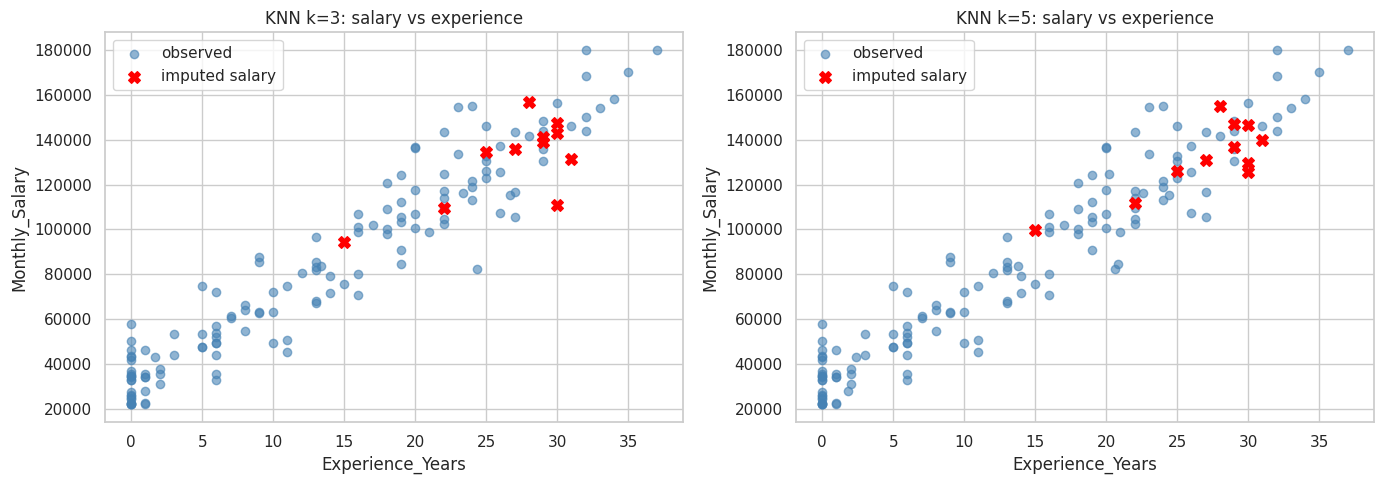

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
miss_s = X["Monthly_Salary"].isna()
for a, Xi, name in zip(ax, [X_knn3, X_knn5], ["KNN k=3", "KNN k=5"]):
    a.scatter(Xi.loc[~miss_s, "Experience_Years"], Xi.loc[~miss_s, "Monthly_Salary"], c="steelblue", alpha=0.6, label="observed")
    a.scatter(Xi.loc[miss_s, "Experience_Years"], Xi.loc[miss_s, "Monthly_Salary"], c="red", s=70, marker="X", label="imputed salary")
    a.set_title(f"{name}: salary vs experience"); a.set_xlabel("Experience_Years"); a.set_ylabel("Monthly_Salary"); a.legend()
plt.tight_layout(); plt.show()

### Does scaling matter? (k=3, scaled vs. unscaled)

In [23]:
diff = (X_knn3 - X_knn3_unscaled).abs()
changed = diff[(X.isna())].stack()
changed = changed[changed > 0]
print("Imputed cells that changed because of scaling:", len(changed), "of", int(X.isna().sum().sum()))
# Example: Satisfaction_Score is imputed using a distance dominated by salary when unscaled
ex = X.index[X["Satisfaction_Score"].isna()][:5]
display(pd.DataFrame({"unscaled_k3": X_knn3_unscaled.loc[ex, "Satisfaction_Score"],
                      "scaled_k3": X_knn3.loc[ex, "Satisfaction_Score"]}).round(2))

Imputed cells that changed because of scaling: 44 of 45


,unscaled_k3,scaled_k3
3,3.67,4.33
17,3.67,2.67
20,3.67,3.33
21,3.67,3.00
22,3.67,4.33


### Interpretation
- **k = 3 vs k = 5:** the imputed values are similar but not identical. With **small k** each fill-in follows only the 3 closest employees, which makes it **more local and flexible but noisier** (higher variance; one odd neighbour moves the estimate a lot). With **larger k** the estimate averages more neighbours, which is **smoother and more stable but more biased toward the overall average** (it blurs local detail). k = 1 would simply copy one neighbour; k = n would reduce to mean imputation.
- **Relationships are preserved much better than with median imputation:** the Experience-Salary correlation stays close to the original under KNN, whereas median imputation weakened it (see Task 4). Imputed salaries (red X in the plot) lie along the experience-salary trend instead of in a flat line at the median.
- **Scaling changes the imputed values.** Without scaling, salary differences (tens of thousands) overwhelm age/experience/satisfaction differences (units of 1-30), so neighbours are effectively chosen by salary alone.
- **Limitations observed:** `Satisfaction_Score` is weakly related to the other columns, so KNN gives it little advantage over the mean; the result is an average (e.g. 3.4) that is not a valid ordinal value, so I round it in the final dataset.

---
# Task 6: Final pipeline and reflection

## 6.1 Choosing k by validation (using known "ground truth")
I cannot know the true value of a cell that is truly missing. So I use a standard trick: take the **111 fully observed rows**, **hide 10% of their values at random**, impute them, and compare to the known truth. This is repeated 30 times with different random masks, and errors are compared for several methods. Error is the RMSE on **standardised** columns so that salary does not dominate (and also reported per column).

In [24]:
complete = X.dropna().reset_index(drop=True)
print("Fully observed rows used for validation:", len(complete))

methods = {
    "mean": ("simple", "mean"), "median": ("simple", "median"),
    "KNN k=3 (unscaled)": ("knn", 3, False),
    "KNN k=3": ("knn", 3, True), "KNN k=5": ("knn", 5, True), "KNN k=10": ("knn", 10, True),
}
rng = np.random.default_rng(RANDOM_STATE)
std = complete.std()
overall, per_col = {m: [] for m in methods}, {m: {c: [] for c in knn_cols} for m in methods}

for rep in range(30):
    mask = pd.DataFrame(rng.random(complete.shape) < 0.10, columns=knn_cols)
    Xm = complete.mask(mask)
    for name, spec in methods.items():
        if spec[0] == "simple":
            out = pd.DataFrame(SimpleImputer(strategy=spec[1]).fit_transform(Xm), columns=knn_cols)
        else:
            out = knn_impute(Xm, k=spec[1], scale=spec[2]).reset_index(drop=True)
        err = (out - complete)
        overall[name].append(np.sqrt((((err / std) ** 2).where(mask)).stack().mean()))
        for c in knn_cols:
            per_col[name][c].append(np.sqrt((err[c][mask[c]] ** 2).mean()))

val = pd.DataFrame({"standardised_RMSE": {m: np.mean(v) for m, v in overall.items()}})
val = val.join(pd.DataFrame({m: {c: np.mean(per_col[m][c]) for c in knn_cols} for m in methods}).T.round(2))
display(val.round(3).sort_values("standardised_RMSE"))

Fully observed rows used for validation: 111


,standardised_RMSE,Age,Experience_Years,Monthly_Salary,Projects_Completed,Satisfaction_Score
KNN k=10,0.744,5.01,4.10,19502.19,2.30,1.20
KNN k=5,0.780,5.08,4.30,21272.27,2.44,1.24
KNN k=3,0.844,5.47,5.09,23504.97,2.60,1.34
KNN k=3 (unscaled),0.912,7.95,8.59,26241.53,2.55,1.29
mean,1.019,10.91,11.43,45493.09,2.14,1.18
median,1.039,10.92,11.80,47809.01,2.13,1.18


### Reading the validation table
- **KNN with scaling beats mean/median** overall, and the gain is large for the **correlated columns** (Age, Experience_Years, Monthly_Salary): the salary error falls from about 45-48k (mean/median) to about 20-24k, and the Age and Experience errors fall by about half.
- **Scaling matters:** unscaled KNN is clearly worse than scaled KNN for the same k.
- **Larger k helps a little here** (k = 10 > 5 > 3). This agrees with the bias-variance explanation: with just 111 complete rows and noisy columns, averaging more neighbours reduces variance.
- **`Projects_Completed` and `Satisfaction_Score` do *not* benefit from KNN** (mean/median is as good or better), because they are essentially unrelated to the other columns. KNN can only help where columns carry information about each other.
- **My choice:** I use **KNN with scaling and k = 5**: it is one of the two k values required for comparison, clearly better than mean/median, and a middle ground between the noisy k = 3 and the more smoothed k = 10 on a small dataset. I note that k = 10 scored slightly better in this experiment; with more data I would tune k formally by cross-validation.
- **Caveat:** this validation assumes values are missing *completely at random*. If salary is truly MNAR (high earners hide it), real-world errors would be larger and biased low, and this experiment cannot detect that.

## 6.2 Final preprocessing workflow (applied to the full dataset)

| Step | Action | Reason |
|---|---|---|
| 1 | Load, inspect, remove 2 exact duplicate rows | Duplicates double-count records. |
| 2 | Keep `Employee_ID` aside, exclude from features | Identifier with no predictive meaning. |
| 3 | Create missingness indicators for `Monthly_Salary` and `Satisfaction_Score` **before** imputing | Being missing may be informative (MAR/MNAR possible). |
| 4 | Scale numerical columns with StandardScaler | KNN distances are scale-sensitive. |
| 5 | KNNImputer (k = 5) on the 5 numeric columns, inverse-scale | Uses relationships between columns. |
| 6 | Round integer-valued columns (Age, Experience, Satisfaction), clip Satisfaction to 1-5 | Keep values valid. |
| 7 | `Performance_Rating`: mode; `Department`: "Unknown" category | Categoricals cannot use KNN-on-numbers; "Unknown" avoids inventing a department. |
| 8 | Verify zero missing values | Check for downstream tools. |

In [25]:
final = df.copy()

# Step 3: missingness indicators (before any imputation)
final["Monthly_Salary_was_missing"] = final["Monthly_Salary"].isna().astype(int)
final["Satisfaction_Score_was_missing"] = final["Satisfaction_Score"].isna().astype(int)

# Steps 4-5: scaled KNN imputation (k=5)
imputed_num = knn_impute(final[knn_cols], k=5, scale=True)

# Step 6: keep valid values
for c in ["Age", "Experience_Years", "Satisfaction_Score"]:
    imputed_num[c] = imputed_num[c].round()
imputed_num["Satisfaction_Score"] = imputed_num["Satisfaction_Score"].clip(1, 5)
imputed_num["Monthly_Salary"] = imputed_num["Monthly_Salary"].round(0)
final[knn_cols] = imputed_num

# Step 7: categorical columns
final["Performance_Rating"] = final["Performance_Rating"].fillna(df["Performance_Rating"].mode()[0])
final["Department"] = final["Department"].fillna("Unknown")

# Step 8: verification
print("Remaining missing values per column:")
print(final.isna().sum())
assert final.isna().sum().sum() == 0
print("\nFinal shape:", final.shape)
final.head()

Remaining missing values per column:
Employee_ID                       0
Age                               0
Experience_Years                  0
Monthly_Salary                    0
Projects_Completed                0
Satisfaction_Score                0
Department                        0
Remote_Work                       0
Performance_Rating                0
Monthly_Salary_was_missing        0
Satisfaction_Score_was_missing    0
dtype: int64

Final shape: (150, 11)


,Employee_ID,Age,Experience_Years,Monthly_Salary,Projects_Completed,Satisfaction_Score,Department,Remote_Work,Performance_Rating,Monthly_Salary_was_missing,Satisfaction_Score_was_missing
0,E001,24.0,0.0,42924.0,4.0,5.0,IT,Yes,Medium,0,0
1,E002,51.0,27.0,143599.0,4.0,4.0,Finance,No,High,0,0
2,E003,47.0,21.0,84579.0,2.0,5.0,IT,No,High,0,0
3,E004,38.0,13.0,68101.0,4.0,4.0,IT,No,Medium,0,1
4,E005,38.0,11.0,50754.0,5.0,5.0,Operations,No,Medium,0,0


In [26]:
# Final check: did imputation distort the original distributions? (Kolmogorov-Smirnov test, observed vs. completed column)
rows = []
for c in knn_cols:
    obs = df[c].dropna()
    stat, p = stats.ks_2samp(obs, final[c])
    rows.append({"column": c, "mean_observed": obs.mean(), "mean_final": final[c].mean(),
                 "std_observed": obs.std(), "std_final": final[c].std(), "KS_stat": stat, "KS_p_value": p})
display(pd.DataFrame(rows).set_index("column").round(3))
final.to_csv("employee_preprocessed_final.csv", index=False)
print("Saved employee_preprocessed_final.csv")

,mean_observed,mean_final,std_observed,std_final,KS_stat,KS_p_value
column,,,,,,
Age,41.191,41.053,10.824,10.783,0.011,1.000
Experience_Years,14.599,14.667,11.013,10.895,0.013,1.000
Monthly_Salary,83951.669,87460.613,43150.199,43572.313,0.046,0.996
Projects_Completed,4.727,4.727,2.189,2.189,0.000,1.000
Satisfaction_Score,3.511,3.513,1.159,1.104,0.023,1.000


Saved employee_preprocessed_final.csv


The means and standard deviations stay close to the observed data. The one visible shift is the **mean salary, which rises from about 83,950 to about 87,460 (+4%)**. This is expected and is actually a sign the method is working: the missing salaries belong to older, more senior staff, so their imputed salaries are above average, whereas median imputation filled them with a below-senior value and left the mean unchanged. The KS tests show **no significant difference** (p-values are large) between the observed distribution and the completed one, so imputation has not visibly distorted the columns. A high p-value is *not* proof of no distortion (the test has low power with n = 150), so this is supporting evidence only.

## 6.3 Avoiding data leakage in predictive modelling
**The problem:** if I imputed and scaled the *whole* dataset before splitting, the training rows would be filled using means, medians or neighbours that include **test-set rows**. Information from the test data leaks into training, making the evaluation look better than it would be on truly new data.

**The fix:** split first, then **fit** the imputer and scaler **only on the training data**, and only **transform** the test data using those learned values (training means/std, training neighbours). In scikit-learn this is done safely with a `Pipeline`, which re-fits the preprocessing inside every cross-validation fold.

Below is a demonstration predicting `Performance_Rating` (rows with a missing target are excluded, since I cannot train or evaluate on an unknown label).

In [27]:
model_df = df.dropna(subset=["Performance_Rating"]).copy()
model_df["Monthly_Salary_was_missing"] = model_df["Monthly_Salary"].isna().astype(int)
model_df["Satisfaction_Score_was_missing"] = model_df["Satisfaction_Score"].isna().astype(int)
model_df["Department"] = model_df["Department"].fillna("Unknown")   # constant fill: no information learned from data, no leakage

y = model_df["Performance_Rating"]
X_model = model_df.drop(columns=["Employee_ID", "Performance_Rating"])

# 1) SPLIT FIRST
X_train, X_test, y_train, y_test = train_test_split(X_model, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

num_features = knn_cols
cat_features = ["Department", "Remote_Work"]
flag_features = ["Monthly_Salary_was_missing", "Satisfaction_Score_was_missing"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("scale", StandardScaler()), ("impute", KNNImputer(n_neighbors=5))]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("flags", "passthrough", flag_features),
])
model = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])

# 2) FIT on training data only (scaler means/stds and KNN neighbours come from training rows)
model.fit(X_train, y_train)

# 3) TRANSFORM (not re-fit) the test data using what was learned from training
print("Test accuracy:", round(model.score(X_test, y_test), 3))
print("Majority-class baseline:", round((y_test == y_test.mode()[0]).mean(), 3))

# Cross-validation: the Pipeline re-fits the imputer/scaler inside each fold -> no leakage
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(model, X_model, y, cv=cv)
print("5-fold CV accuracy:", scores.round(3), "| mean:", scores.mean().round(3))

Test accuracy: 0.444
Majority-class baseline: 0.528
5-fold CV accuracy: [0.517 0.414 0.464 0.571 0.464] | mean: 0.486


**Note:** accuracy is at or below the majority-class baseline. That is expected: performance rating here looks only weakly related to the other columns (this is a synthetic practice dataset). The demonstration is about **correct procedure** (no leakage), not model quality.

## 6.4 How I would evaluate imputation quality if ground truth were available
1. **Pointwise error** between imputed and true values: **RMSE / MAE** for numerical columns (done in 6.1 by masking known values), and **accuracy** for categorical columns.
2. **Distribution comparison:** compare the imputed vs. true distributions (mean, std, histograms, **KS test**) to check the spread has not collapsed.
3. **Relationship preservation:** compare correlations and regression coefficients before vs. after.
4. **Downstream performance:** train the model on each imputed version and compare test performance.
5. **Repeat across several random masks** and report the average and spread, not a single run.
6. Mask values using a mechanism that resembles the suspected real one (e.g., hide salary for the *senior* staff, not only at random), because MAR/MNAR gaps are harder than MCAR gaps.

## 6.5 Limitations of my choices
- **Mechanism uncertainty:** the data cannot prove whether salary is MAR or MNAR. If high earners hide their salary (MNAR), KNN will **underestimate** it, because neighbours are chosen from observed (lower on average) salaries.
- **Salary floor/cap:** the 22,000 and 180,000 limits are censored values. KNN cannot recover the true values beyond these limits.
- **Small dataset (150 rows, 111 complete):** KNN neighbours are few, and the choice of k is noisy.
- **Single imputation:** each missing cell gets one value, so downstream standard errors are too small. **Multiple imputation** (e.g., `IterativeImputer` with `sample_posterior=True`) would reflect the uncertainty.
- **Ordinal and categorical treatment:** Satisfaction is treated as numeric (then rounded). Department and Performance_Rating use constant/mode fills, which ignore relationships with other columns. Mode imputation inflates the "Medium" class.
- **Equal feature weights in the distance:** Age and Experience are almost the same information (correlation 0.95), so together they count twice in the distance.

---
# Conclusion
After removing 2 duplicate records, I analysed missingness in six columns (all below 12%). Missingness was **not clustered across columns**. Monthly_Salary missingness was strongly associated with age and experience, so **MCAR is unlikely for salary**; whether it is MAR or MNAR cannot be proven from this dataset and needs domain information. Simple mean/median/mode imputation is easy but flattens variability and weakens correlations. My final strategy is **scaled KNN imputation (k = 5)** for the numerical columns, **missingness indicators** for salary and satisfaction, the **mode** for Performance_Rating and an **"Unknown" category** for Department. Validation by masking known values showed KNN clearly outperforming mean/median for the correlated columns (Age, Experience, Salary), but not for Satisfaction and Projects, which are nearly unrelated to the rest. For predictive modelling, all imputers and scalers must be **fitted on training data only**, which a scikit-learn `Pipeline` guarantees.